## 1. Setup

In [4]:
!pip install -q ultralytics==8.4.202 pycocotools


In [3]:
import gc, os, shutil, subprocess, time
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np
import pandas as pd
import torch
import yaml
from google.colab import auth, drive
from PIL import Image
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
from torchvision.ops import box_iou
from tqdm.auto import tqdm
from ultralytics import YOLO

In [4]:
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Device:', torch.cuda.get_device_name(0) if DEVICE == 'cuda' else 'CPU - turn on the GPU runtime')

auth.authenticate_user()
email = subprocess.getoutput('gcloud config get-value account')
print('Current Google User:', email)

Device: Tesla T4
Current Google User: rasthkp@gmail.com


In [5]:
DRIVE_ROOT = '/content/drive/MyDrive/datasets/hw2_train-s3_val-s3/'

In [6]:
OUT = Path('/content/drive/MyDrive/hw2_runs/yolo')  # weights, tables, figures, submission
WORK = Path('/content/yolo_data')                   # labels and links for YOLO, rebuilt on each run

WEIGHTS = 'yolov8s.pt'
EPOCHS = 1              # final model
EXP_EPOCHS = 2          # each parameter experiment
EXP_TRAIN_IMAGES = 2000 # same subset sizes as the two-stage notebook
EXP_VAL_IMAGES = 500

BATCH_SIZE = 4
MAX_DET = 300           # scenes are dense
SCORE_THRESH = 0.01     # low threshold is standard for mAP

drive.mount('/content/drive', force_remount=True)
ROOT = Path(DRIVE_ROOT)
OUT.mkdir(parents=True, exist_ok=True)

Mounted at /content/drive


In [7]:
drive.mount('/content/drive', force_remount=True)
ROOT = Path(DRIVE_ROOT)

if not ROOT.exists():
    print('Copying dataset to local disk...')
    shutil.copytree(DRIVE_ROOT, ROOT)

Mounted at /content/drive


##  Data

YOLO labels are written from `annotations_coco.json`, the same file evaluation uses, so training and evaluation can't disagree and the frames match the two-stage notebook. Frames missing from disk are skipped, and frames with no objects stay in as background examples. Images are linked from Drive, not copied.

In [14]:
names = yaml.safe_load(open(ROOT / 'train' / 'data.yaml'))['names']
names = [names[k] for k in sorted(names)] if isinstance(names, dict) else names
NUM_CLASSES = len(names)


class CocoFrames:
    def __init__(self, split, limit=None):
        self.coco = COCO(str(ROOT / split / 'annotations_coco.json'))

        # Remove annotations with an unlisted category or zero size, for training and evaluation alike
        anns = self.coco.dataset['annotations']
        good = [a for a in anns if a['category_id'] in self.coco.cats and a['bbox'][2] > 0 and a['bbox'][3] > 0]
        for a in good:
            a.setdefault('iscrowd', 0)
            a.setdefault('area', a['bbox'][2] * a['bbox'][3])
        self.coco.dataset['annotations'] = good
        self.coco.createIndex()

        # Images are in <split>/ or <split>/images/. Keep only frames that exist on disk.
        for self.folder in [ROOT / split, ROOT / split / 'images']:
            self.ids = [i for i, im in sorted(self.coco.imgs.items()) if (self.folder / im['file_name']).exists()]
            if self.ids:
                break
        assert self.ids, f'No images from the {split} json were found on disk'
        total = len(self.ids)
        if limit and limit < total:  # evenly spaced, so every clip stays represented
            self.ids = [self.ids[k] for k in np.linspace(0, total - 1, limit).astype(int)]

        self.cat2cls = {c['id']: names.index(c['name']) for c in self.coco.cats.values()}  # 0-based, as in data.yaml
        print(f'{split}: using {len(self.ids):,} frames ({len(self.coco.imgs):,} in json, {total:,} on disk), '
              f'dropped {len(anns) - len(good):,} bad annotations')

    def path(self, image_id):
        return self.folder / self.coco.imgs[image_id]['file_name']

    def frames(self):
        return {str(self.path(i)): i for i in self.ids}

    def boxes_and_labels(self, image_id):
        boxes, labels = [], []
        for a in self.coco.imgToAnns[image_id]:
            x, y, w, h = a['bbox']
            if not a['iscrowd']:
                boxes.append([x, y, x + w, y + h])
                labels.append(self.cat2cls[a['category_id']])
        return torch.tensor(boxes, dtype=torch.float32).reshape(-1, 4), torch.tensor(labels, dtype=torch.int64)

    def write_yolo(self, name):
        """Creates WORK/<name>/images (links to Drive) and WORK/<name>/labels (class x_center y_center w h, 0 to 1)."""
        shutil.rmtree(WORK / name, ignore_errors=True)
        (WORK / name / 'images').mkdir(parents=True)
        (WORK / name / 'labels').mkdir(parents=True)
        for image_id in self.ids:
            im = self.coco.imgs[image_id]
            os.symlink(self.path(image_id), WORK / name / 'images' / f'{image_id}{self.path(image_id).suffix}')
            boxes, labels = self.boxes_and_labels(image_id)
            lines = []
            for c, (x1, y1, x2, y2) in zip(labels.tolist(), boxes.tolist()):
                x1, x2 = max(x1, 0), min(x2, im['width'])
                y1, y2 = max(y1, 0), min(y2, im['height'])
                if x2 > x1 and y2 > y1:
                    lines.append(f"{c} {(x1 + x2) / 2 / im['width']:.6f} {(y1 + y2) / 2 / im['height']:.6f} "
                                 f"{(x2 - x1) / im['width']:.6f} {(y2 - y1) / im['height']:.6f}")
            (WORK / name / 'labels' / f'{image_id}.txt').write_text('\n'.join(lines))
        return name


def test_frames():
    return {str(p): f'{p.parent.name}_{p.stem}' for p in sorted((ROOT / 'test' / 'images').rglob('*.jpg'))}


train_ds, val_ds = CocoFrames('train'), CocoFrames('val')
exp_train, exp_val = CocoFrames('train', limit=EXP_TRAIN_IMAGES), CocoFrames('val', limit=EXP_VAL_IMAGES)
for name, ds in [('train', train_ds), ('val', val_ds), ('exp_train', exp_train), ('exp_val', exp_val)]:
    ds.write_yolo(name)
print(NUM_CLASSES, 'classes:', names)

loading annotations into memory...
Done (t=5.87s)
creating index...
index created!
creating index...
index created!
train: using 8,090 frames (24,201 in json, 8,090 on disk), dropped 0 bad annotations
loading annotations into memory...
Done (t=0.49s)
creating index...
index created!
creating index...
index created!
val: using 951 frames (2,846 in json, 951 on disk), dropped 0 bad annotations
loading annotations into memory...
Done (t=6.93s)
creating index...
index created!
creating index...
index created!
train: using 2,000 frames (24,201 in json, 8,090 on disk), dropped 0 bad annotations
loading annotations into memory...
Done (t=0.47s)
creating index...
index created!
creating index...
index created!
val: using 500 frames (2,846 in json, 951 on disk), dropped 0 bad annotations
8 classes: ['person', 'bicycle', 'car', 'van', 'truck', 'tricycle', 'bus', 'motor']


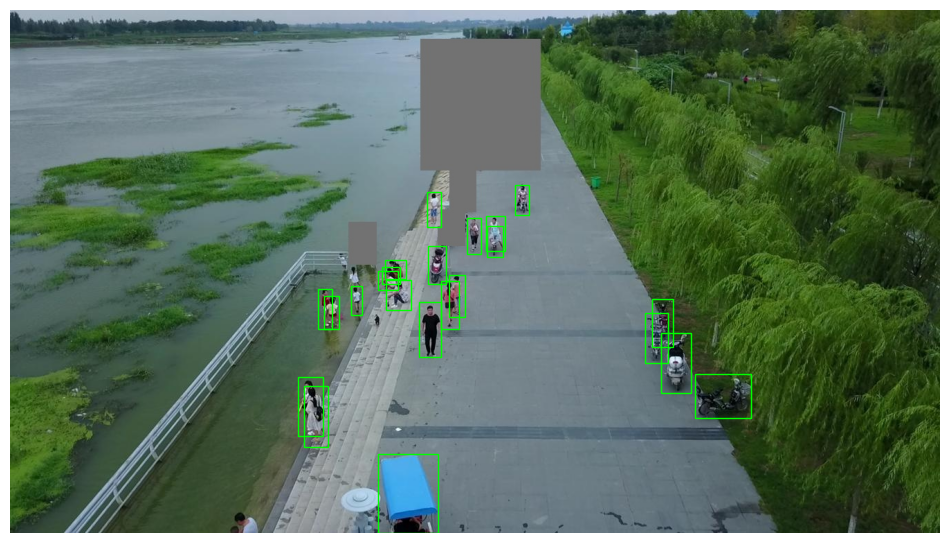

In [8]:
image_id = train_ds.ids[0]
image = Image.open(WORK / 'train' / 'images' / f'{image_id}{train_ds.path(image_id).suffix}').convert('RGB')
W, H = image.size
fig, ax = plt.subplots(figsize=(12, 7))
ax.imshow(image)
for line in (WORK / 'train' / 'labels' / f'{image_id}.txt').read_text().splitlines():
    _, xc, yc, w, h = map(float, line.split())
    ax.add_patch(patches.Rectangle(((xc - w / 2) * W, (yc - h / 2) * H), w * W, h * H, fill=False, color='lime', linewidth=1))
ax.axis('off')
plt.show()

## 3. Model and training setup

| Item | Choice | Why |
|---|---|---|
| Model | Ultralytics YOLOv8s, COCO-pretrained | Anchor-free: each grid location predicts a class and its distances to the box sides, with no anchor boxes to design |
| Classifier head | Rebuilt by Ultralytics for this dataset's classes | COCO classes don't match this dataset |
| Label assignment and box loss | Task-aligned assigner, CIoU + distribution focal loss (library defaults, not tuned here) | Standard for this model |
| Input size | Tuned below | Small objects need enough pixels |
| Detection head | Standard P3-P5, or extra P2 head (tuned below) | P2 adds stride 4 features for tiny objects |
| Optimizer | Ultralytics `auto` | Selects the optimizer and learning rate from the training length |
| Warmup | 0.1 epoch instead of 3 | The default would use the whole 1-epoch run for warmup |
| Augmentation | Library defaults without mosaic | Mosaic reads 4 images per sample, which is slow from Drive in a run this short |
| Epochs | 1 | Time limit. The two-stage notebook planned 6, so compare the results with that in mind |

In [9]:
def train_model(name, epochs, train, val, imgsz, cfg=None):
    """Trains and saves to OUT/<name>_<epochs>ep.pt. An existing file is used as is.
    Delete the file to retrain. An interrupted run restarts from the beginning."""
    path = OUT / f'{name}_{epochs}ep.pt'
    if path.exists():
        print(f'{name}: loading {path}')
        return YOLO(str(path))

    data = WORK / f'{name}.yaml'
    data.write_text(yaml.safe_dump({'path': str(WORK), 'train': f'{train}/images', 'val': f'{val}/images', 'names': names}))
    model = YOLO(cfg).load(WEIGHTS) if cfg else YOLO(WEIGHTS)  # cfg: changed architecture, matching weights are reused
    model.train(data=str(data), epochs=epochs, imgsz=imgsz, batch=BATCH_SIZE, workers=2, seed=0,
                warmup_epochs=0.1, mosaic=0.0, val=False, plots=False,
                project=str(OUT / 'runs'), name=f'{name}_{epochs}ep', exist_ok=True)

    temp = path.with_suffix('.tmp')
    shutil.copy(model.trainer.best, temp)
    temp.replace(path)  # the file only appears once training has fully finished
    return YOLO(str(path))

## 4. Prediction and evaluation

`predict` returns `{image_id: (cls, scores, boxes)}` with 0-based classes and `x1, y1, x2, y2` boxes, the same format as the two-stage notebook. `coco_eval` is the same function too, so the numbers can be compared directly.

In [8]:
def predict(model, frames, imgsz):
    # A text file of paths reads images batch by batch. A Python list would load them all into RAM first.
    list_file = Path('/tmp/predict_frames.txt')
    list_file.write_text('\n'.join(frames))

    results = {}
    for r in tqdm(model.predict(source=str(list_file), imgsz=imgsz, conf=SCORE_THRESH, max_det=MAX_DET,
                                batch=8, stream=True, verbose=False), total=len(frames), desc='predict'):
        b = r.boxes
        results[frames[r.path]] = (b.cls.cpu().numpy().astype(int), b.conf.cpu().numpy(), b.xyxy.cpu().numpy())
    assert len(results) == len(frames), f'Predicted {len(results)} of {len(frames)} frames'
    return results


def coco_eval(results, dataset):
    cls2cat = {k: cat for cat, k in dataset.cat2cls.items()}
    detections = [
        {'image_id': image_id, 'category_id': cls2cat[int(c)], 'score': float(s),
         'bbox': [float(x1), float(y1), float(x2 - x1), float(y2 - y1)]}
        for image_id, (cls, scores, boxes) in results.items()
        for c, s, (x1, y1, x2, y2) in zip(cls, scores, boxes)
    ]
    assert detections, 'The model produced no detections'
    ev = COCOeval(dataset.coco, dataset.coco.loadRes(detections), 'bbox')
    ev.params.imgIds = dataset.ids  # only the frames in the subset
    ev.params.maxDets = [1, 10, MAX_DET]
    ev.evaluate()
    ev.accumulate()

    precision = ev.eval['precision']  # [IoU threshold, recall, class, area range, max detections]
    def mean_ap(p):
        return float(p[p > -1].mean()) if (p > -1).any() else float('nan')
    metrics = {'mAP': mean_ap(precision[:, :, :, 0, -1]),
               'AP50': mean_ap(precision[0, :, :, 0, -1]),
               'AP_small': mean_ap(precision[:, :, :, 1, -1])}
    per_class = {names[dataset.cat2cls[cat]]: mean_ap(precision[:, :, k, 0, -1]) for k, cat in enumerate(ev.params.catIds)}
    return metrics, per_class


def inference_ms(model, dataset, imgsz, n=100):
    """Milliseconds per image for the model itself, one image at a time, without file loading."""
    images = [cv2.imread(str(dataset.path(i))) for i in dataset.ids[:n]]
    run = lambda image: model.predict(image, imgsz=imgsz, conf=SCORE_THRESH, max_det=MAX_DET, verbose=False)
    run(images[0])  # the first call sets up the predictor, so it isn't timed
    if DEVICE == 'cuda':
        torch.cuda.synchronize()
    start = time.perf_counter()
    for image in images:
        run(image)
    if DEVICE == 'cuda':
        torch.cuda.synchronize()
    return 1000 * (time.perf_counter() - start) / len(images)

## 5. Parameter study

Two parameters are compared, with everything else fixed:

1. **Input resolution:** a larger input gives small objects more pixels, at the cost of speed and memory.
2. **Additional high-resolution head (P2):** detects on stride 4 features as well, which suits tiny objects.

These runs are short and use part of the data, so compare them with each other, not with the final model.

In [10]:

from concurrent.futures import ThreadPoolExecutor

ROOT = Path('/content/hw2_data')

def copy_one(src):
    dst = ROOT / src.relative_to(DRIVE_ROOT)
    if dst.exists():
        return
    dst.parent.mkdir(parents=True, exist_ok=True)
    temp = dst.with_name(dst.name + '.part')
    shutil.copy(src, temp)
    temp.replace(dst)

files = [p for p in Path(DRIVE_ROOT).rglob('*') if p.is_file()]
print(f'Copying {len(files):,} files...')
with ThreadPoolExecutor(16) as pool:
    list(tqdm(pool.map(copy_one, files), total=len(files)))

Copying 21,903 files...


  0%|          | 0/21903 [00:00<?, ?it/s]

In [13]:
TRAIN_NOW = True  # True: train only. False: evaluate models already on Drive. Restart the session between the two.
RUN_NOW = ['baseline', 'imgsz_640', 'p2_head']  # names from EXPERIMENTS

EXPERIMENTS = {
    'baseline':   {'imgsz': 960},
    'imgsz_640':  {'imgsz': 640},
    'imgsz_1280': {'imgsz': 1280},
    'p2_head':    {'imgsz': 960, 'cfg': 'yolov8s-p2.yaml'},
}

# Training only needs the label files from here on, so free the large train annotations
train_ds = exp_train = None  # safe to run this cell again
gc.collect()

csv_path = OUT / 'experiments.csv'
rows = pd.read_csv(csv_path).to_dict('records') if csv_path.exists() else []
done = {r['run'] for r in rows}

for name in RUN_NOW:
    params = EXPERIMENTS[name]
    model = train_model(name, EXP_EPOCHS, 'exp_train', 'exp_val', **params)
    if not TRAIN_NOW and name not in done:
        metrics, _ = coco_eval(predict(model, exp_val.frames(), params['imgsz']), exp_val)
        rows.append({'run': name, **metrics, 'ms_per_image': inference_ms(model, exp_val, params['imgsz'])})
        pd.DataFrame(rows).round(4).to_csv(csv_path, index=False)  # saved after every run
    del model
    gc.collect()
    torch.cuda.empty_cache()

if rows:
    experiments = pd.DataFrame(rows).set_index('run').round(4)
    best_run = experiments['mAP'].idxmax()
    print('Best run:', best_run)
    display(experiments)

baseline: loading /content/drive/MyDrive/hw2_runs/yolo/baseline_2ep.pt
Ultralytics 8.4.202 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/yolo_data/imgsz_640.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=2, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=0.0, multi_scal

##  Final model and validation results

In [10]:
names = yaml.safe_load(open(ROOT / 'train' / 'data.yaml'))['names']
names = [names[k] for k in sorted(names)] if isinstance(names, dict) else names
NUM_CLASSES = len(names)


class ValFrames:
    def __init__(self):
        self.coco = COCO(str(ROOT / 'val' / 'annotations_coco.json'))

        # Remove annotations with an unlisted category or zero size, as in section 2
        anns = self.coco.dataset['annotations']
        good = [a for a in anns if a['category_id'] in self.coco.cats and a['bbox'][2] > 0 and a['bbox'][3] > 0]
        for a in good:
            a.setdefault('iscrowd', 0)
            a.setdefault('area', a['bbox'][2] * a['bbox'][3])
        self.coco.dataset['annotations'] = good
        self.coco.createIndex()

        # Images are in val/ or val/images/. Keep only frames that exist on disk.
        for self.folder in [ROOT / 'val', ROOT / 'val' / 'images']:
            self.ids = [i for i, im in sorted(self.coco.imgs.items()) if (self.folder / im['file_name']).exists()]
            if self.ids:
                break
        assert self.ids, 'No images from the val json were found on disk'

        self.cat2cls = {c['id']: names.index(c['name']) for c in self.coco.cats.values()}  # 0-based, as in data.yaml
        print(f'val: using {len(self.ids):,} frames ({len(self.coco.imgs):,} in json), '
              f'dropped {len(anns) - len(good):,} bad annotations')

    def path(self, image_id):
        return self.folder / self.coco.imgs[image_id]['file_name']

    def frames(self):
        return {str(self.path(i)): i for i in self.ids}

    def boxes_and_labels(self, image_id):
        boxes, labels = [], []
        for a in self.coco.imgToAnns[image_id]:
            x, y, w, h = a['bbox']
            if not a['iscrowd']:
                boxes.append([x, y, x + w, y + h])
                labels.append(self.cat2cls[a['category_id']])
        return torch.tensor(boxes, dtype=torch.float32).reshape(-1, 4), torch.tensor(labels, dtype=torch.int64)


val_ds = ValFrames()
print(NUM_CLASSES, 'classes:', names)

loading annotations into memory...
Done (t=0.52s)
creating index...
index created!
creating index...
index created!
val: using 951 frames (2,846 in json), dropped 0 bad annotations
8 classes: ['person', 'bicycle', 'car', 'van', 'truck', 'tricycle', 'bus', 'motor']


In [7]:
runs = {}
for csv_file in sorted((OUT / 'runs').glob('*/results.csv')):
    name = csv_file.parent.name  # for example baseline_2ep
    if name.startswith('final') or not (OUT / f'{name}.pt').exists():
        print('Skipping', name)
        continue
    log = pd.read_csv(csv_file)
    log.columns = log.columns.str.strip()
    args = yaml.safe_load(open(csv_file.parent / 'args.yaml'))
    runs[name] = {'imgsz': args['imgsz'], **log.iloc[-1].to_dict()}  # the last row has the validation metrics

assert runs, f'No finished runs found in {OUT / "runs"}'
comparison = pd.DataFrame(runs).T.astype(float).sort_values('metrics/mAP50-95(B)', ascending=False)
comparison.to_csv(OUT / 'runs_comparison.csv')
best_name = comparison['metrics/mAP50-95(B)'].idxmax()
print('Best model:', best_name)
comparison.T.round(4)

Best model: baseline_2ep


,baseline_2ep,imgsz_640_2ep,p2_head_2ep
imgsz,960.0000,640.0000,960.0000
epoch,2.0000,2.0000,2.0000
time,1070.6500,159.0030,253.9470
train/box_loss,1.6848,1.7907,2.2078
train/cls_loss,1.2120,1.2809,2.1225
train/dfl_loss,1.1028,1.0126,2.3030
metrics/precision(B),0.3767,0.3013,0.1547
metrics/recall(B),0.3872,0.3406,0.2310
metrics/mAP50(B),0.2904,0.2488,0.1537
metrics/mAP50-95(B),0.1482,0.1246,0.0720


In [11]:
imgsz = 960
model = YOLO(str(OUT / f'baseline_2ep.pt'))
print(f'Validating baseline_2ep.pt at input size {imgsz}')

val_results = predict(model, val_ds.frames(), imgsz)
metrics, per_class = coco_eval(val_results, val_ds)
ms = inference_ms(model, val_ds, imgsz)

report = pd.Series({**metrics, 'ms_per_image': ms, 'FPS': 1000 / ms}).round(4)
report.to_csv(OUT / 'best_model_metrics.csv')
per_class = pd.Series(per_class, name='AP per class').sort_values().round(4)
per_class.to_csv(OUT / 'best_model_per_class.csv')
print(report, '\n')
print(per_class)

Validating baseline_2ep.pt at input size 960


predict:   0%|          | 0/951 [00:00<?, ?it/s]

Loading and preparing results...
DONE (t=0.54s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=74.62s).
Accumulating evaluation results...
DONE (t=1.57s).
mAP              0.1354
AP50             0.2661
AP_small         0.0569
ms_per_image    22.4142
FPS             44.6146
dtype: float64 

bus         0.0052
van         0.0559
motor       0.0879
bicycle     0.0993
truck       0.1110
tricycle    0.1213
person      0.2513
car         0.3511
Name: AP per class, dtype: float64


## Submission

In [12]:
def make_submission(model, imgsz):
    """Predicts every test image and returns {image_id: (cls, scores, boxes)}. Nothing is written to disk."""
    return predict(model, test_frames(), imgsz)  # always every test image, never a subset


def save_submission(results, path):
    """Writes predictions as: image_id,PredictionString with "cls score x y w h" for each box.
    Every test image gets a row, and a frame with no boxes gets an empty PredictionString."""
    def to_text(cls, scores, boxes):
        return ' '.join(f'{c} {s:.4f} {x1:.1f} {y1:.1f} {x2 - x1:.1f} {y2 - y1:.1f}'
                        for c, s, (x1, y1, x2, y2) in zip(cls, scores, boxes))

    submission = pd.DataFrame({'image_id': sorted(results)})
    submission['PredictionString'] = submission['image_id'].map(lambda image_id: to_text(*results[image_id]))
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    submission.to_csv(path, index=False)
    print(f'Saved {path} with {len(submission):,} rows')
    return submission

In [15]:
test_results = make_submission(model, imgsz)
print(f'Predicted {len(test_results):,} test images')

predict:   0%|          | 0/3811 [00:00<?, ?it/s]

Predicted 3,811 test images


In [16]:
# If saving fails, fix the path and re-run only this cell: test_results stays in memory
submission = save_submission(test_results, OUT / 'submission_yolo.csv')
submission.head()

Saved /content/drive/MyDrive/hw2_runs/yolo/submission_yolo.csv with 3,811 rows


,image_id,PredictionString
0,clip_001_0000001,0 0.8563 975.4 712.6 37.2 100.6 0 0.8169 830.8...
1,clip_001_0000002,0 0.8241 831.0 712.7 37.9 107.3 0 0.8240 974.2...
2,clip_001_0000003,0 0.8320 829.5 714.0 39.6 107.7 0 0.7628 718.1...
3,clip_001_0000004,0 0.7781 672.8 769.6 46.2 128.7 0 0.7762 1721....
4,clip_001_0000005,0 0.8048 1661.0 807.4 59.8 145.8 0 0.7539 1160...


Note: due to the lack of compute capabilities, some workarounds are introduced in this notebook (like loading only the eval indexes per session). The Colab computing capabilities is also the reason for the low score.